In [1]:
# ============================================================
# Heart Disease Prediction — Full ML Portfolio Project
# Author: Vyshnavi Sunil Kumar
# Dataset: Heart Failure Prediction (Kaggle / UCI)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 6)
sns.set_theme(style='whitegrid')

print("All libraries loaded successfully!")

All libraries loaded successfully!


In [2]:
# Load dataset
df = pd.read_csv('heart.csv')

# First look
print("Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Shape: (918, 12)

First 5 rows:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
print("Data types & non-null counts:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nBasic statistics:")
df.describe()

Data types & non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB
None

Missing values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR     

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


Target class distribution:
HeartDisease
1    508
0    410
Name: count, dtype: int64

HeartDisease
1    55.3
0    44.7 %

--- Suspicious zeros ---
RestingBP == 0: 1 rows
Cholesterol == 0: 172 rows


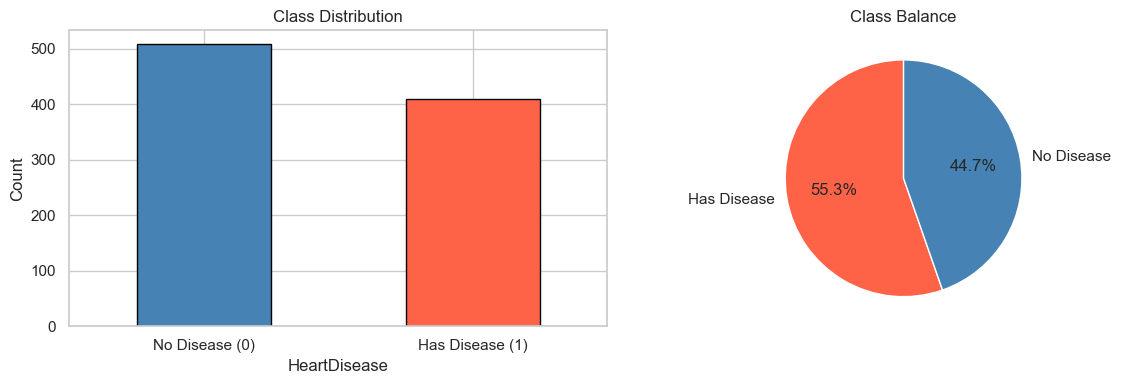

In [4]:
print("Target class distribution:")
print(df['HeartDisease'].value_counts())
print(f"\n{df['HeartDisease'].value_counts(normalize=True).mul(100).round(1).to_string()} %")

print("\n--- Suspicious zeros ---")
print(f"RestingBP == 0: {(df['RestingBP'] == 0).sum()} rows")
print(f"Cholesterol == 0: {(df['Cholesterol'] == 0).sum()} rows")

# Visualise class balance
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['HeartDisease'].value_counts().plot(kind='bar', ax=axes[0], color=['steelblue','tomato'], edgecolor='black')
axes[0].set_title('Class Distribution')
axes[0].set_xticklabels(['No Disease (0)', 'Has Disease (1)'], rotation=0)
axes[0].set_ylabel('Count')

axes[1].pie(df['HeartDisease'].value_counts(), labels=['Has Disease', 'No Disease'],
            autopct='%1.1f%%', colors=['tomato','steelblue'], startangle=90)
axes[1].set_title('Class Balance')

plt.tight_layout()
plt.show()

In [5]:
# Drop the 1 row where RestingBP is 0
df = df[df['RestingBP'] != 0].reset_index(drop=True)
print(f"After dropping RestingBP==0: {df.shape}")

# Replace Cholesterol zeros with median (calculated only from non-zero values)
chol_median = df[df['Cholesterol'] != 0]['Cholesterol'].median()
df['Cholesterol'] = df['Cholesterol'].replace(0, chol_median)
print(f"Cholesterol zeros replaced with median: {chol_median}")

# Verify no more zeros
print(f"\nRemaining Cholesterol zeros: {(df['Cholesterol'] == 0).sum()}")
print(f"Remaining RestingBP zeros: {(df['RestingBP'] == 0).sum()}")
print(f"\nFinal dataset shape: {df.shape}")

After dropping RestingBP==0: (917, 12)
Cholesterol zeros replaced with median: 237.0

Remaining Cholesterol zeros: 0
Remaining RestingBP zeros: 0

Final dataset shape: (917, 12)


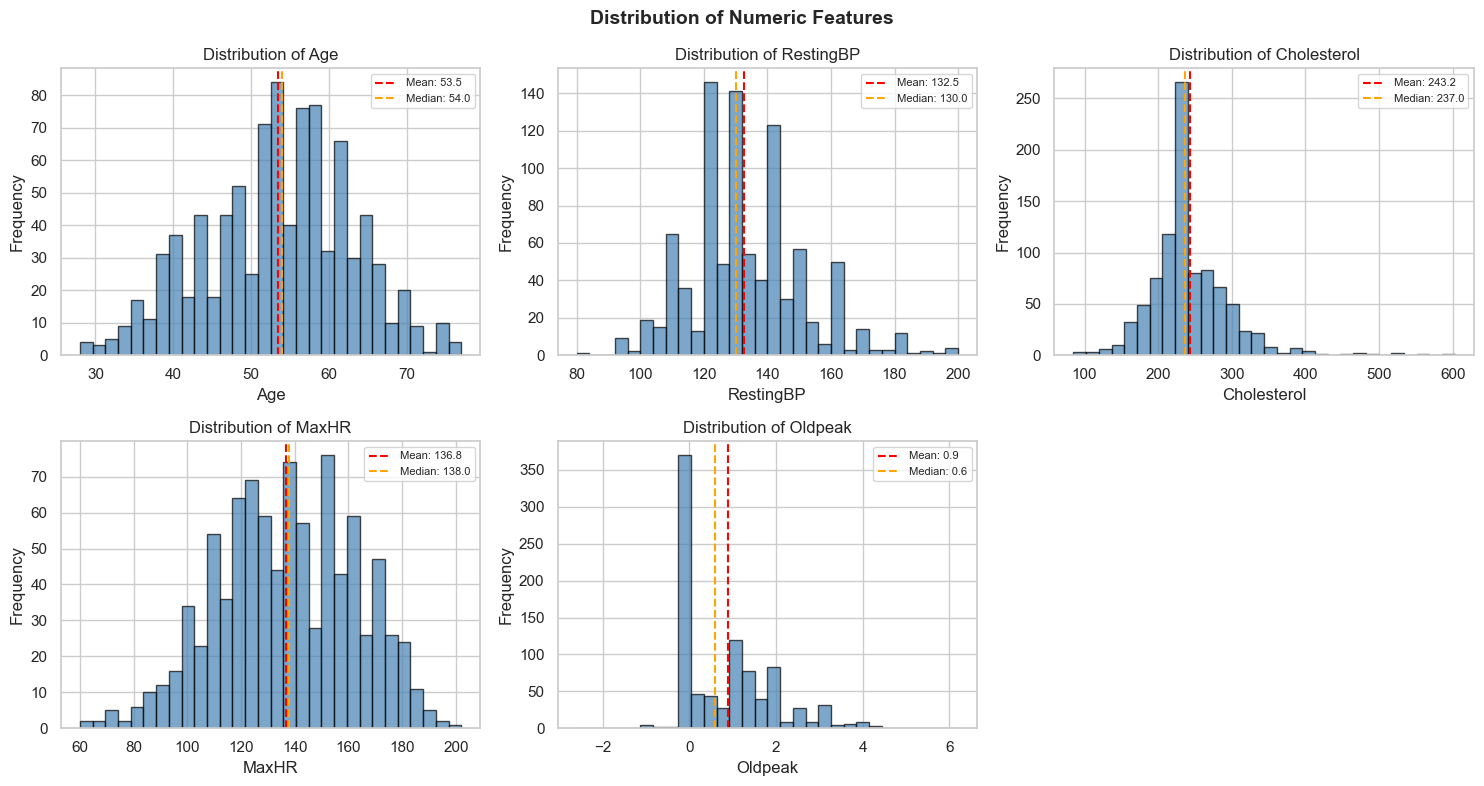

In [6]:
numeric_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
    axes[i].axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean: {df[col].mean():.1f}')
    axes[i].axvline(df[col].median(), color='orange', linestyle='--', label=f'Median: {df[col].median():.1f}')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].legend(fontsize=8)

# Hide the unused 6th subplot
axes[5].set_visible(False)

plt.suptitle('Distribution of Numeric Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

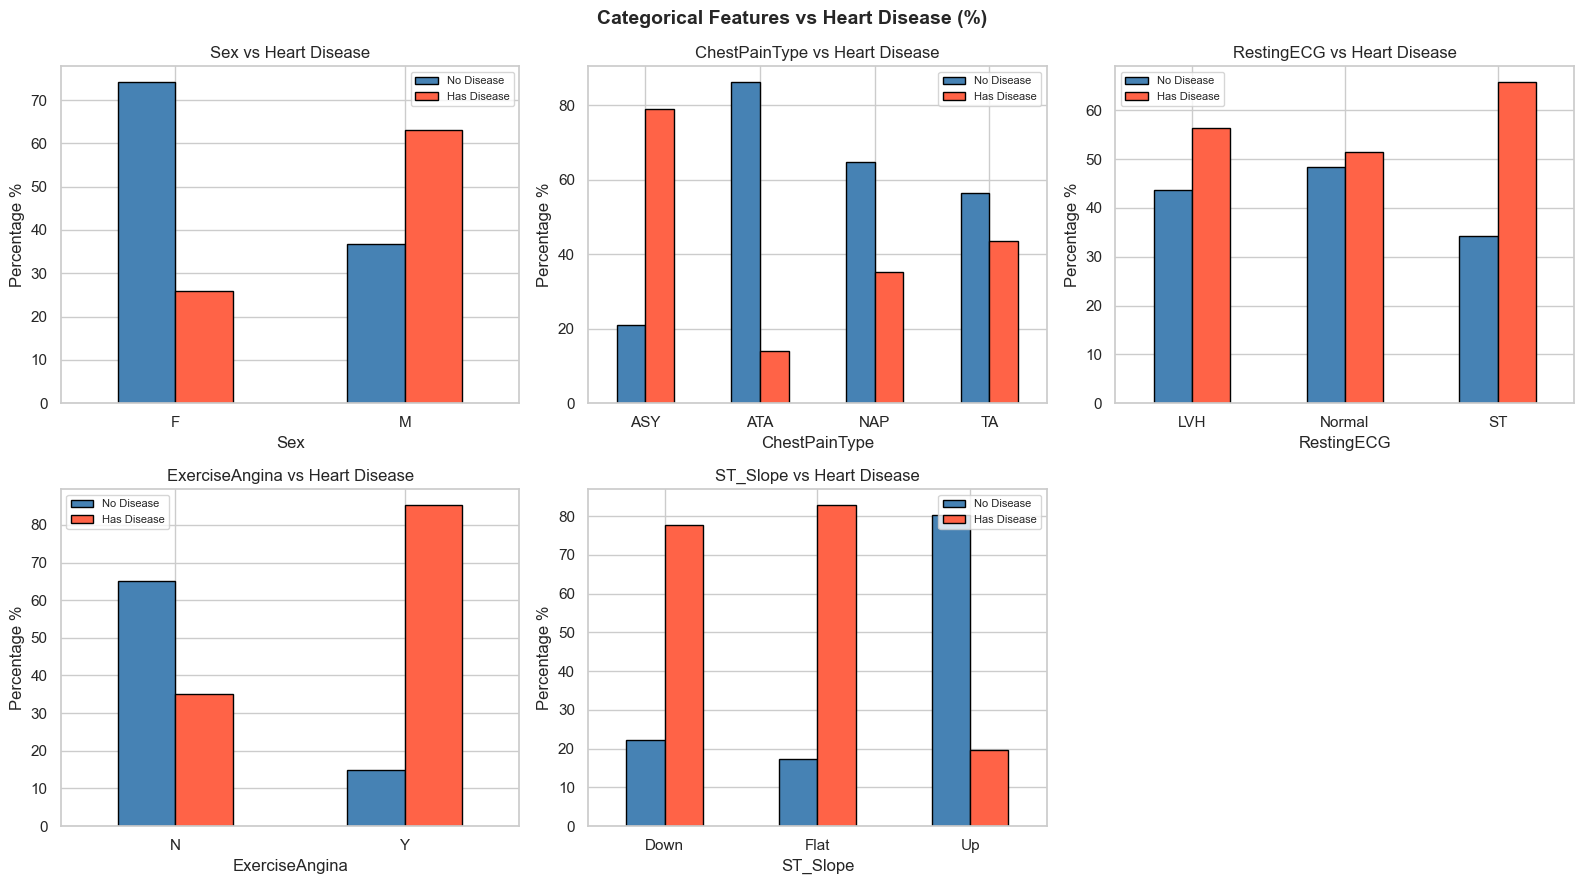

In [7]:
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    ct = df.groupby(col)['HeartDisease'].value_counts(normalize=True).mul(100).unstack()
    ct.plot(kind='bar', ax=axes[i], color=['steelblue', 'tomato'], edgecolor='black')
    axes[i].set_title(f'{col} vs Heart Disease')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Percentage %')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=0)
    axes[i].legend(['No Disease', 'Has Disease'], fontsize=8)

axes[5].set_visible(False)

plt.suptitle('Categorical Features vs Heart Disease (%)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

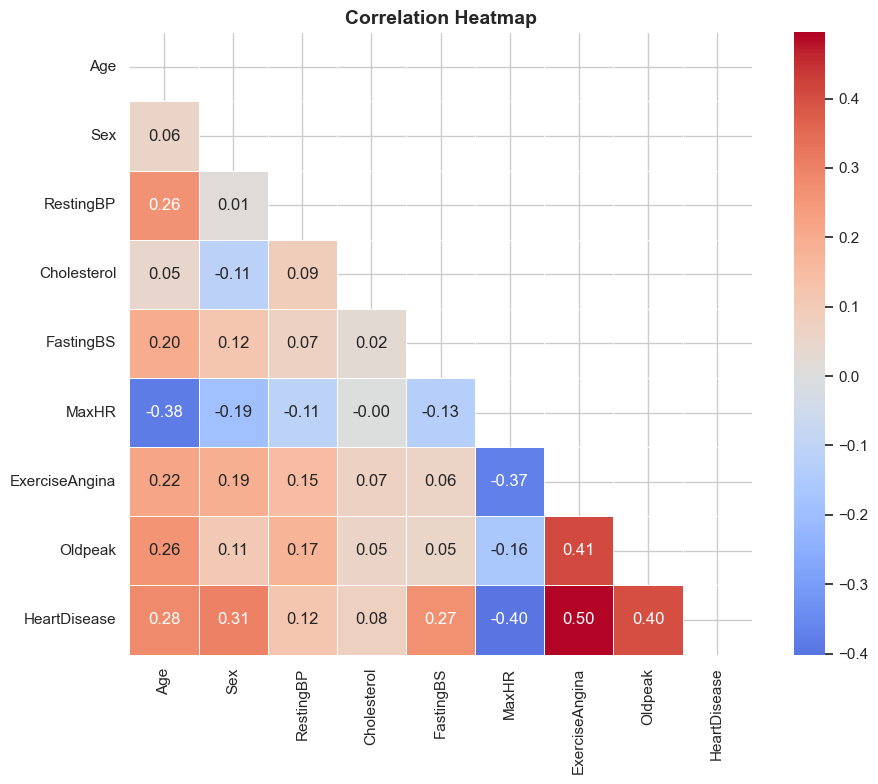


Top correlations with HeartDisease:
ExerciseAngina    0.495490
Oldpeak           0.403638
MaxHR            -0.401410
Sex               0.305118
Age               0.282012
FastingBS         0.267994
RestingBP         0.117990
Cholesterol       0.076262
Name: HeartDisease, dtype: float64


In [8]:
# Encode binary categoricals temporarily just for correlation
df_corr = df.copy()
df_corr['Sex'] = df_corr['Sex'].map({'M': 1, 'F': 0})
df_corr['ExerciseAngina'] = df_corr['ExerciseAngina'].map({'Y': 1, 'N': 0})

numeric_for_corr = ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS',
                    'MaxHR', 'ExerciseAngina', 'Oldpeak', 'HeartDisease']

corr_matrix = df_corr[numeric_for_corr].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5)
plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nTop correlations with HeartDisease:")
print(corr_matrix['HeartDisease'].drop('HeartDisease').sort_values(key=abs, ascending=False))

In [9]:
# Encode all categorical columns
df_model = df.copy()

# Binary encoding
df_model['Sex'] = df_model['Sex'].map({'M': 1, 'F': 0})
df_model['ExerciseAngina'] = df_model['ExerciseAngina'].map({'Y': 1, 'N': 0})

# One-hot encoding for multi-class categoricals
df_model = pd.get_dummies(df_model, columns=['ChestPainType', 'RestingECG', 'ST_Slope'], drop_first=False)

print("Columns after encoding:")
print(df_model.columns.tolist())
print(f"\nShape: {df_model.shape}")

# Separate features and target
X = df_model.drop('HeartDisease', axis=1)
y = df_model['HeartDisease']

# Scale features
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# Train/test split (80/20, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTraining set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")
print(f"\nClass balance in training set:")
print(y_train.value_counts())

Columns after encoding:
['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'HeartDisease', 'ChestPainType_ASY', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Down', 'ST_Slope_Flat', 'ST_Slope_Up']

Shape: (917, 19)

Training set: (733, 18)
Test set:     (184, 18)

Class balance in training set:
HeartDisease
1    405
0    328
Name: count, dtype: int64


  File "C:\Users\vyshn\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\vyshn\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\vyshn\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\vyshn\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


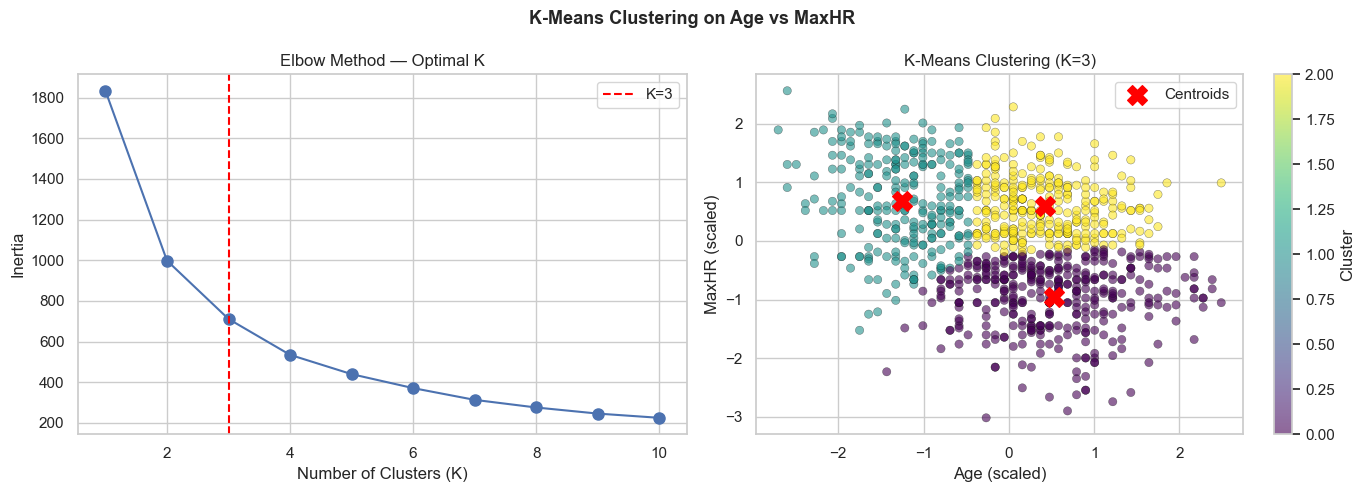

Cluster sizes: {0: 368, 1: 254, 2: 295}


In [10]:
# ── SECTION 2: CLUSTERING (Week 3) ──────────────────────────

# Use only 2 numeric features for visualisation
X_cluster = X_scaled[['Age', 'MaxHR']].values

# Find optimal K using inertia (elbow method)
inertias = []
K_range = range(1, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster)
    inertias.append(km.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
axes[0].plot(K_range, inertias, 'bo-', markersize=8)
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method — Optimal K')
axes[0].axvline(x=3, color='red', linestyle='--', label='K=3')
axes[0].legend()

# K=3 clustering result
km_final = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = km_final.fit_predict(X_cluster)

scatter = axes[1].scatter(X_cluster[:, 0], X_cluster[:, 1],
                           c=clusters, cmap='viridis', alpha=0.6, edgecolors='k', linewidths=0.3)
axes[1].scatter(km_final.cluster_centers_[:, 0], km_final.cluster_centers_[:, 1],
                c='red', marker='X', s=200, label='Centroids')
axes[1].set_xlabel('Age (scaled)')
axes[1].set_ylabel('MaxHR (scaled)')
axes[1].set_title('K-Means Clustering (K=3)')
axes[1].legend()
plt.colorbar(scatter, ax=axes[1], label='Cluster')

plt.suptitle('K-Means Clustering on Age vs MaxHR', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Cluster sizes: {pd.Series(clusters).value_counts().sort_index().to_dict()}")

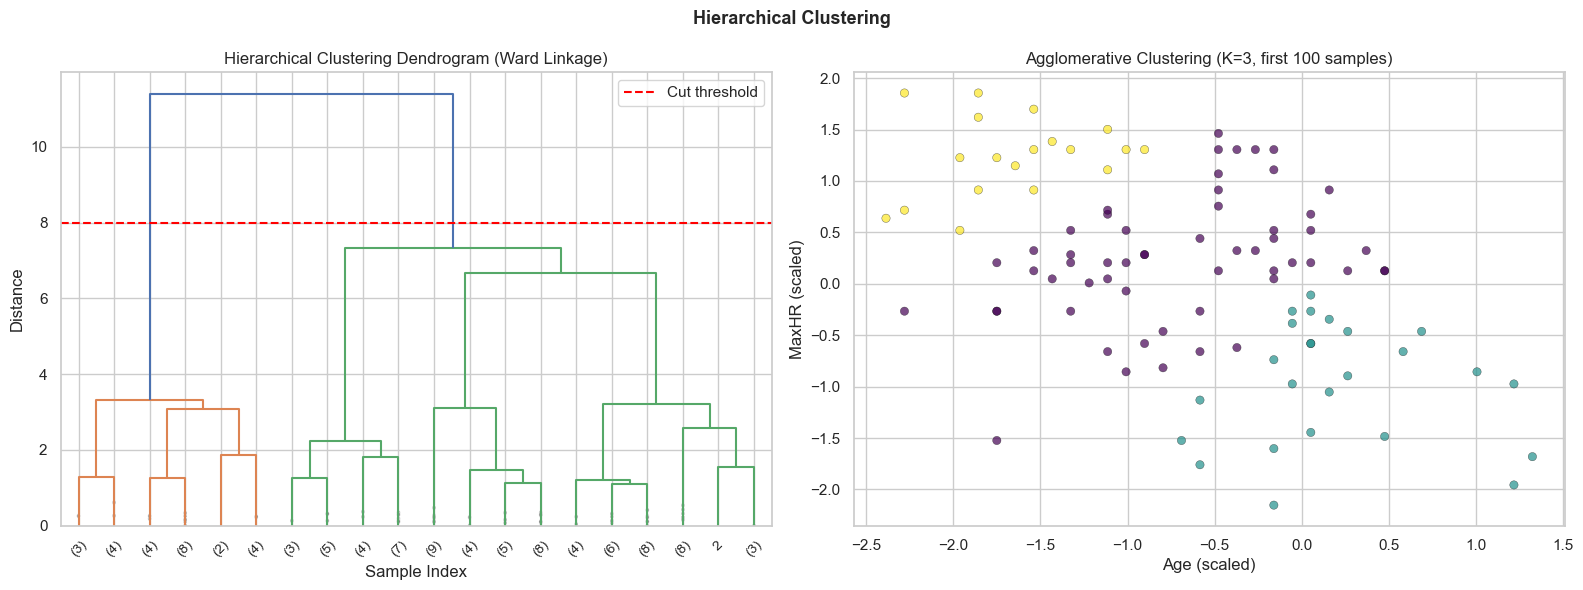

Agglomerative cluster sizes: {0: 56, 1: 25, 2: 19}


In [11]:
# Hierarchical clustering on same 2 features
X_hier = X_scaled[['Age', 'MaxHR']].values[:100]  # use 100 rows so dendrogram is readable

# Compute linkage matrix
linked = linkage(X_hier, method='ward')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Dendrogram
dendrogram(linked, ax=axes[0], truncate_mode='lastp', p=20,
           leaf_rotation=45, leaf_font_size=10, show_contracted=True)
axes[0].set_title('Hierarchical Clustering Dendrogram (Ward Linkage)')
axes[0].set_xlabel('Sample Index')
axes[0].set_ylabel('Distance')
axes[0].axhline(y=8, color='red', linestyle='--', label='Cut threshold')
axes[0].legend()

# Agglomerative clustering result
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg.fit_predict(X_hier)

axes[1].scatter(X_hier[:, 0], X_hier[:, 1], c=agg_labels,
                cmap='viridis', alpha=0.7, edgecolors='k', linewidths=0.3)
axes[1].set_title('Agglomerative Clustering (K=3, first 100 samples)')
axes[1].set_xlabel('Age (scaled)')
axes[1].set_ylabel('MaxHR (scaled)')

plt.suptitle('Hierarchical Clustering', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Agglomerative cluster sizes:", pd.Series(agg_labels).value_counts().sort_index().to_dict())

Coefficient (slope): -1.0316
Intercept:           191.5020
R² score:            0.1382
RMSE:                23.8044

Interpretation: For every 1 year increase in age,
MaxHR decreases by 1.03 bpm on average.


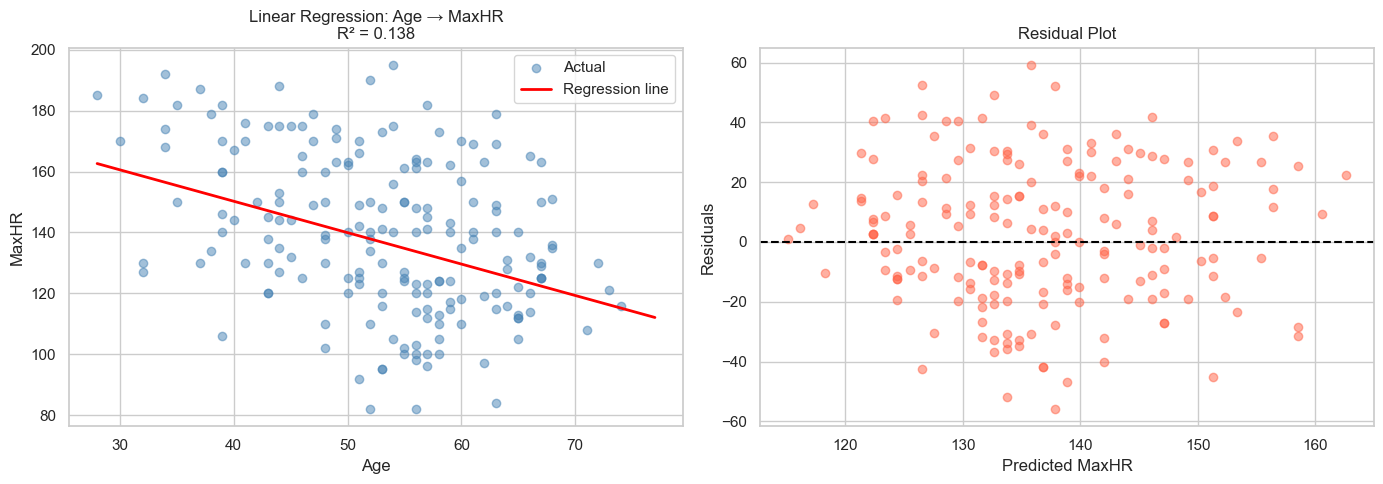

In [12]:
# ── SECTION 3: LINEAR REGRESSION (Week 4) ───────────────────

# Use Age to predict MaxHR (continuous target — classic regression)
X_lr = df[['Age']].values
y_lr = df['MaxHR'].values

X_lr_train, X_lr_test, y_lr_train, y_lr_test = train_test_split(
    X_lr, y_lr, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_lr_train, y_lr_train)
y_lr_pred = lr.predict(X_lr_test)

# Metrics
from sklearn.metrics import mean_squared_error, r2_score
r2 = r2_score(y_lr_test, y_lr_pred)
rmse = np.sqrt(mean_squared_error(y_lr_test, y_lr_pred))

print(f"Coefficient (slope): {lr.coef_[0]:.4f}")
print(f"Intercept:           {lr.intercept_:.4f}")
print(f"R² score:            {r2:.4f}")
print(f"RMSE:                {rmse:.4f}")
print(f"\nInterpretation: For every 1 year increase in age,")
print(f"MaxHR decreases by {abs(lr.coef_[0]):.2f} bpm on average.")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Regression line
x_line = np.linspace(X_lr.min(), X_lr.max(), 100).reshape(-1, 1)
axes[0].scatter(X_lr_test, y_lr_test, alpha=0.5, color='steelblue', label='Actual')
axes[0].plot(x_line, lr.predict(x_line), color='red', linewidth=2, label='Regression line')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('MaxHR')
axes[0].set_title(f'Linear Regression: Age → MaxHR\nR² = {r2:.3f}')
axes[0].legend()

# Residuals
residuals = y_lr_test - y_lr_pred
axes[1].scatter(y_lr_pred, residuals, alpha=0.5, color='tomato')
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_xlabel('Predicted MaxHR')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot')

plt.tight_layout()
plt.show()

── Logistic Regression ──
Accuracy: 0.8804

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.87      0.87      0.87        82
 Has Disease       0.89      0.89      0.89       102

    accuracy                           0.88       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.88      0.88      0.88       184



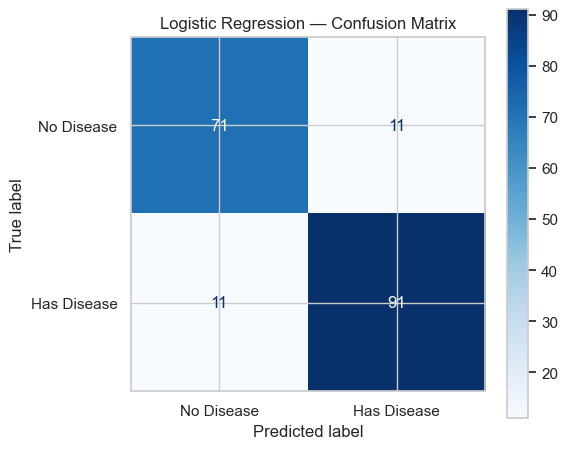

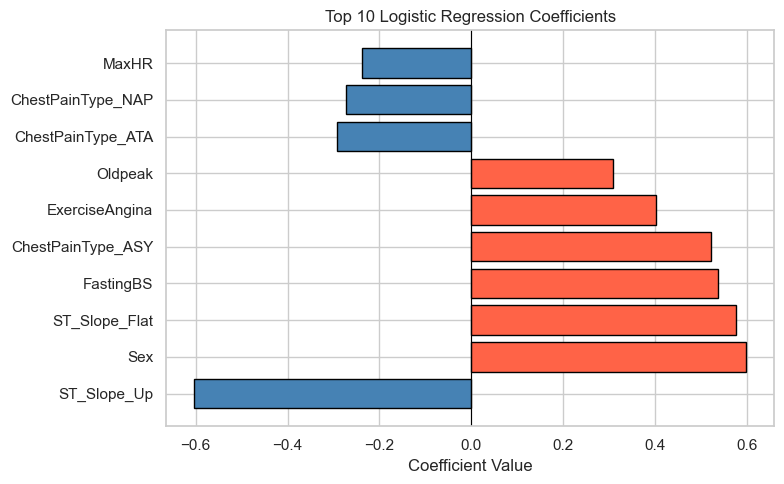

In [13]:
# ── SECTION 4: LOGISTIC REGRESSION (Week 4) ─────────────────

log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_test)

print("── Logistic Regression ──")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, target_names=['No Disease', 'Has Disease']))

# Confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr,
    display_labels=['No Disease', 'Has Disease'],
    cmap='Blues', ax=ax)
ax.set_title('Logistic Regression — Confusion Matrix')
plt.tight_layout()
plt.show()

# Feature coefficients (top 10)
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': log_reg.coef_[0]
}).sort_values('Coefficient', key=abs, ascending=False).head(10)

plt.figure(figsize=(8, 5))
colors = ['tomato' if c > 0 else 'steelblue' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors, edgecolor='black')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 10 Logistic Regression Coefficients')
plt.xlabel('Coefficient Value')
plt.tight_layout()
plt.show()

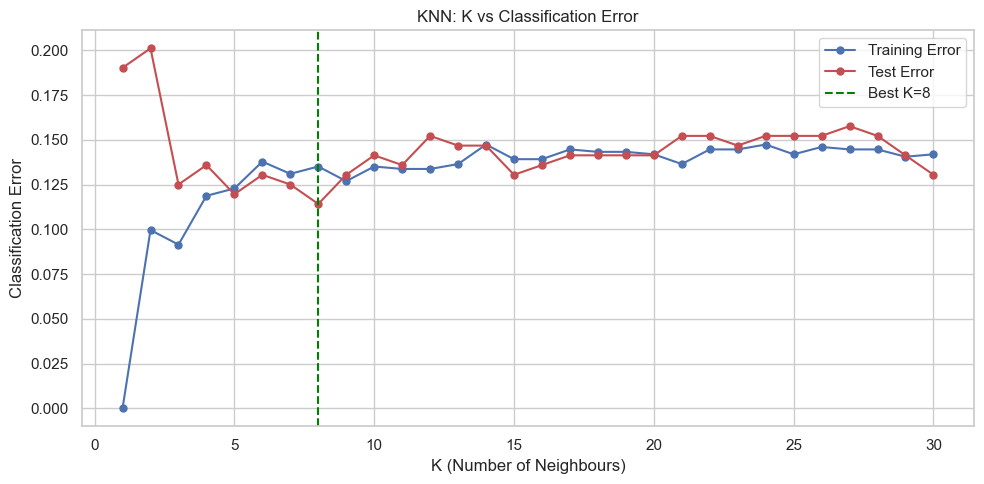

Best K: 8
── KNN (K=8) ──
Accuracy: 0.8859

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.86      0.89      0.87        82
 Has Disease       0.91      0.88      0.90       102

    accuracy                           0.89       184
   macro avg       0.88      0.89      0.88       184
weighted avg       0.89      0.89      0.89       184



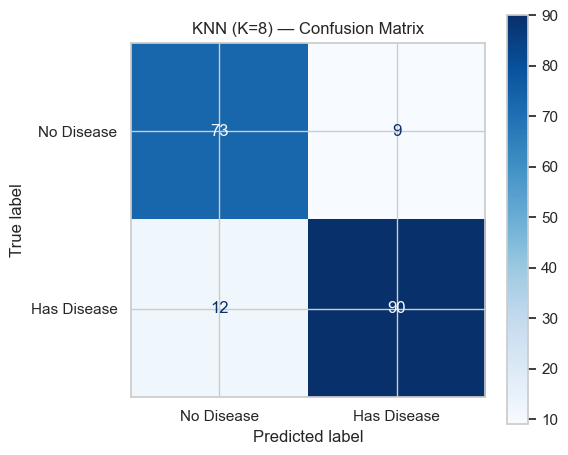

In [14]:
# ── SECTION 5: KNN CLASSIFICATION (Week 6) ──────────────────

# Try different values of K
k_values = range(1, 31)
train_errors = []
test_errors = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    train_errors.append(1 - knn.score(X_train, y_train))
    test_errors.append(1 - knn.score(X_test, y_test))

# Plot K vs error
plt.figure(figsize=(10, 5))
plt.plot(k_values, train_errors, 'bo-', label='Training Error', markersize=5)
plt.plot(k_values, test_errors, 'ro-', label='Test Error', markersize=5)
best_k = k_values[np.argmin(test_errors)]
plt.axvline(x=best_k, color='green', linestyle='--', label=f'Best K={best_k}')
plt.xlabel('K (Number of Neighbours)')
plt.ylabel('Classification Error')
plt.title('KNN: K vs Classification Error')
plt.legend()
plt.tight_layout()
plt.show()

# Train final KNN with best K
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train, y_train)
y_pred_knn = knn_final.predict(X_test)

print(f"Best K: {best_k}")
print(f"── KNN (K={best_k}) ──")
print(f"Accuracy: {accuracy_score(y_test, y_pred_knn):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn, target_names=['No Disease', 'Has Disease']))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn,
    display_labels=['No Disease', 'Has Disease'],
    cmap='Blues', ax=ax)
ax.set_title(f'KNN (K={best_k}) — Confusion Matrix')
plt.tight_layout()
plt.show()

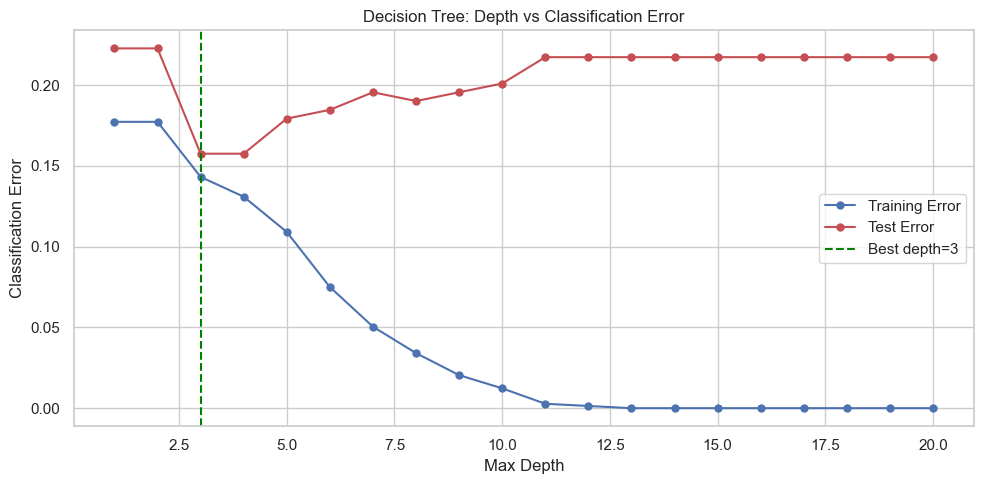

Best depth: 3
── Decision Tree (depth=3) ──
Accuracy: 0.8424

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.81      0.84      0.83        82
 Has Disease       0.87      0.84      0.86       102

    accuracy                           0.84       184
   macro avg       0.84      0.84      0.84       184
weighted avg       0.84      0.84      0.84       184



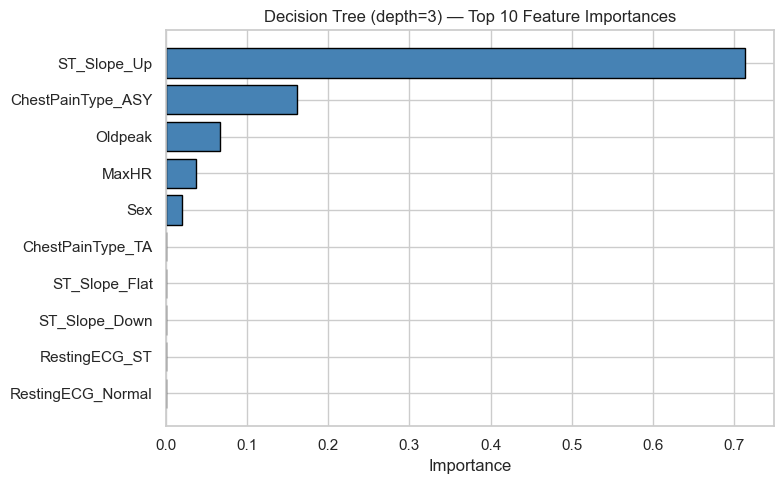

In [15]:
# ── SECTION 6: DECISION TREE (Week 7) ───────────────────────

# Tune max_depth
depths = range(1, 21)
train_errors_dt = []
test_errors_dt = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)
    train_errors_dt.append(1 - dt.score(X_train, y_train))
    test_errors_dt.append(1 - dt.score(X_test, y_test))

best_depth = depths[np.argmin(test_errors_dt)]

plt.figure(figsize=(10, 5))
plt.plot(depths, train_errors_dt, 'bo-', label='Training Error', markersize=5)
plt.plot(depths, test_errors_dt, 'ro-', label='Test Error', markersize=5)
plt.axvline(x=best_depth, color='green', linestyle='--', label=f'Best depth={best_depth}')
plt.xlabel('Max Depth')
plt.ylabel('Classification Error')
plt.title('Decision Tree: Depth vs Classification Error')
plt.legend()
plt.tight_layout()
plt.show()

# Train final Decision Tree
dt_final = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt_final.fit(X_train, y_train)
y_pred_dt = dt_final.predict(X_test)

print(f"Best depth: {best_depth}")
print(f"── Decision Tree (depth={best_depth}) ──")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, target_names=['No Disease', 'Has Disease']))

# Feature importances
feat_imp = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': dt_final.feature_importances_
}).sort_values('Importance', ascending=False).head(10)

plt.figure(figsize=(8, 5))
plt.barh(feat_imp['Feature'], feat_imp['Importance'], color='steelblue', edgecolor='black')
plt.title(f'Decision Tree (depth={best_depth}) — Top 10 Feature Importances')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

── Random Forest ──
Best params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Accuracy: 0.8750

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.86      0.85      0.86        82
 Has Disease       0.88      0.89      0.89       102

    accuracy                           0.88       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.87      0.88      0.87       184


── Gradient Boosting ──
Best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Accuracy: 0.8913

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.89      0.87      0.88        82
 Has Disease       0.89      0.91      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.89      0.89       184
weighted avg       0.89      0.89      0.89       184



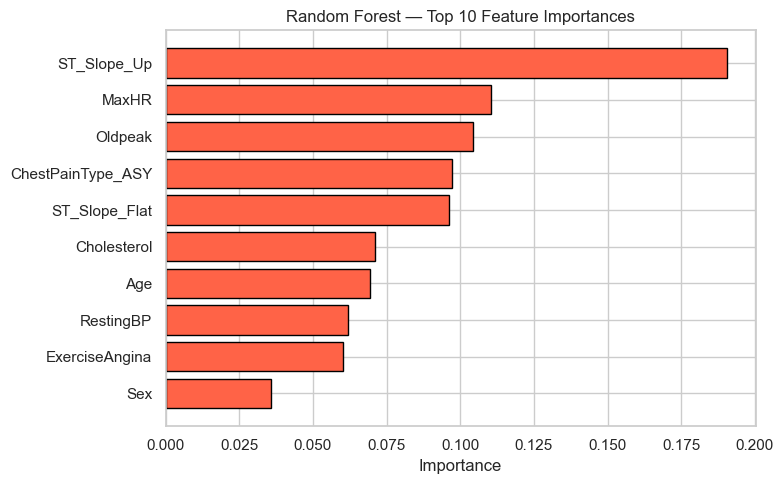

In [16]:
# ── SECTION 7: ENSEMBLE METHODS (Week 8) ────────────────────

# Random Forest with GridSearchCV
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5]
}

rf = RandomForestClassifier(random_state=42)
rf_grid = GridSearchCV(rf, rf_params, cv=5, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train, y_train)

rf_best = rf_grid.best_estimator_
y_pred_rf = rf_best.predict(X_test)

print("── Random Forest ──")
print(f"Best params: {rf_grid.best_params_}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['No Disease', 'Has Disease']))

# Gradient Boosting
gb_params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1]
}

gb = GradientBoostingClassifier(random_state=42)
gb_grid = GridSearchCV(gb, gb_params, cv=5, scoring='accuracy', n_jobs=-1)
gb_grid.fit(X_train, y_train)

gb_best = gb_grid.best_estimator_
y_pred_gb = gb_best.predict(X_test)

print("\n── Gradient Boosting ──")
print(f"Best params: {gb_grid.best_params_}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_gb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb, target_names=['No Disease', 'Has Disease']))

# Feature importances — Random Forest
feat_imp_rf = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_best.feature_importances_
}).sort_values('Importance', ascending=False).head(10)

plt.figure(figsize=(8, 5))
plt.barh(feat_imp_rf['Feature'], feat_imp_rf['Importance'], color='tomato', edgecolor='black')
plt.title('Random Forest — Top 10 Feature Importances')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

── Naive Bayes ──
Accuracy: 0.8587

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.85      0.83      0.84        82
 Has Disease       0.87      0.88      0.87       102

    accuracy                           0.86       184
   macro avg       0.86      0.86      0.86       184
weighted avg       0.86      0.86      0.86       184


Predicted probabilities (first 5 samples):
Sample     P(No Disease)        P(Has Disease)       Predicted
-----------------------------------------------------------------
1          0.6206               0.3794               No Disease
2          0.0000               1.0000               Has Disease
3          0.0063               0.9937               Has Disease
4          0.0000               1.0000               Has Disease
5          0.9983               0.0017               No Disease


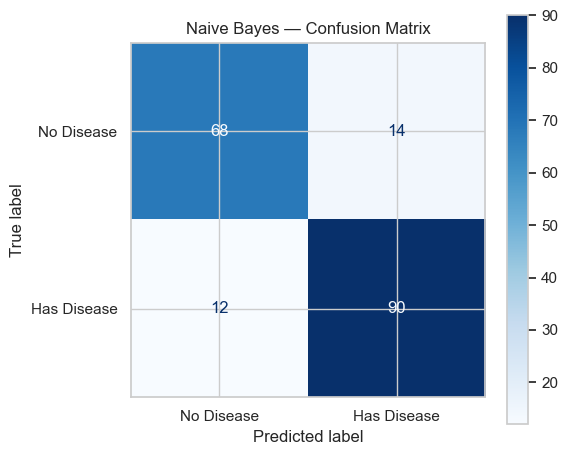

In [17]:
# ── SECTION 8: NAIVE BAYES (Week 9) ─────────────────────────

nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

print("── Naive Bayes ──")
print(f"Accuracy: {accuracy_score(y_test, y_pred_nb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb, target_names=['No Disease', 'Has Disease']))

# Class probabilities for first 5 test samples
proba = nb.predict_proba(X_test[:5])
print("\nPredicted probabilities (first 5 samples):")
print(f"{'Sample':<10} {'P(No Disease)':<20} {'P(Has Disease)':<20} {'Predicted'}")
print("-" * 65)
for i, (p, pred) in enumerate(zip(proba, nb.predict(X_test[:5]))):
    label = 'Has Disease' if pred == 1 else 'No Disease'
    print(f"{i+1:<10} {p[0]:<20.4f} {p[1]:<20.4f} {label}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nb,
    display_labels=['No Disease', 'Has Disease'],
    cmap='Blues', ax=ax)
ax.set_title('Naive Bayes — Confusion Matrix')
plt.tight_layout()
plt.show()

── Neural Network (MLP) ──
Best params: {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (128,), 'max_iter': 500}
Accuracy: 0.8370

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.80      0.84      0.82        82
 Has Disease       0.87      0.83      0.85       102

    accuracy                           0.84       184
   macro avg       0.83      0.84      0.84       184
weighted avg       0.84      0.84      0.84       184



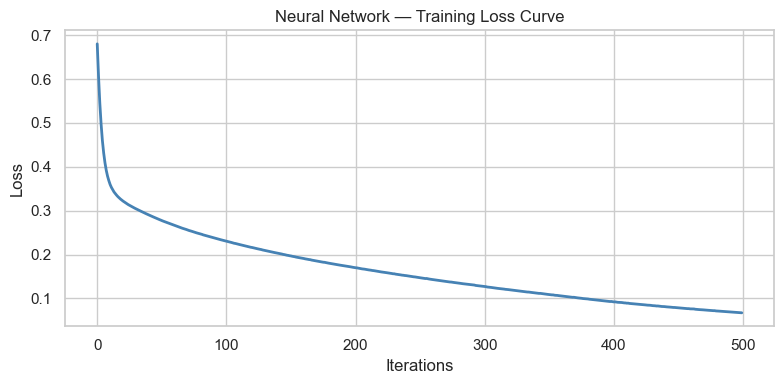

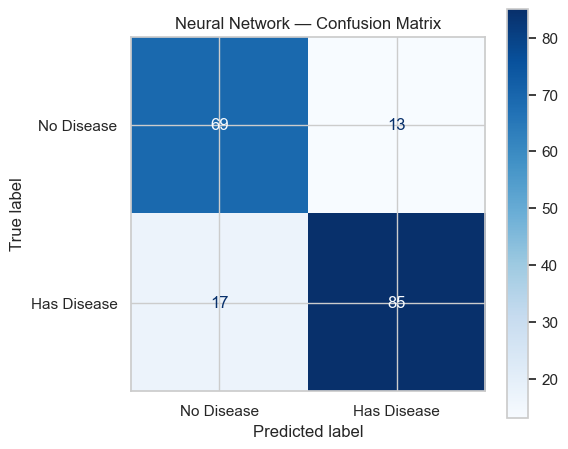

In [18]:
# ── SECTION 9: NEURAL NETWORK (Week 10-11) ──────────────────

from sklearn.neural_network import MLPClassifier

# Tune hidden layer sizes
nn_params = {
    'hidden_layer_sizes': [(64,), (128,), (64, 32), (128, 64)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001],        # L2 regularisation
    'max_iter': [500]
}

nn = MLPClassifier(random_state=42)
nn_grid = GridSearchCV(nn, nn_params, cv=5, scoring='accuracy', n_jobs=-1)
nn_grid.fit(X_train, y_train)

nn_best = nn_grid.best_estimator_
y_pred_nn = nn_best.predict(X_test)

print("── Neural Network (MLP) ──")
print(f"Best params: {nn_grid.best_params_}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_nn):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nn, target_names=['No Disease', 'Has Disease']))

# Plot loss curve
plt.figure(figsize=(8, 4))
plt.plot(nn_best.loss_curve_, color='steelblue', linewidth=2)
plt.title('Neural Network — Training Loss Curve')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nn,
    display_labels=['No Disease', 'Has Disease'],
    cmap='Blues', ax=ax)
ax.set_title('Neural Network — Confusion Matrix')
plt.tight_layout()
plt.show()

Model                       Mean Acc      Std      Min      Max
-----------------------------------------------------------------
Logistic Regression           0.8582   0.0324   0.8197   0.9076
KNN (K=8)                     0.8342   0.0262   0.7923   0.8634
Decision Tree                 0.8473   0.0221   0.8087   0.8750
Random Forest                 0.8658   0.0278   0.8251   0.9022
Gradient Boosting             0.8505   0.0337   0.8033   0.9076
Naive Bayes                   0.8397   0.0286   0.8098   0.8913
Neural Network                0.8168   0.0193   0.7869   0.8415


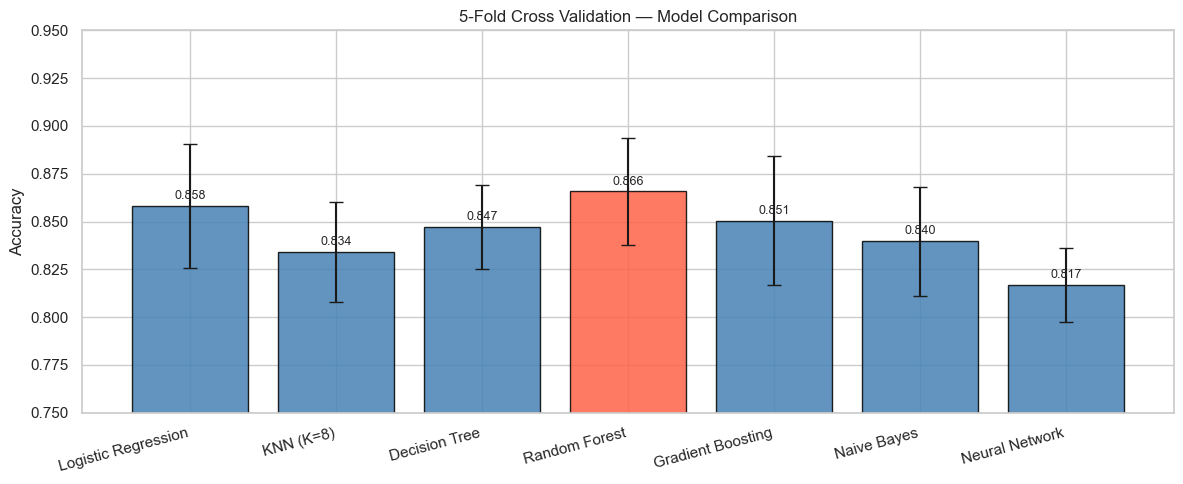

In [19]:
# ── SECTION 10: MODEL COMPARISON WITH K-FOLD CV ─────────────

kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'KNN (K=8)':           KNeighborsClassifier(n_neighbors=best_k),
    'Decision Tree':       DecisionTreeClassifier(max_depth=best_depth, random_state=42),
    'Random Forest':       RandomForestClassifier(**rf_grid.best_params_, random_state=42),
    'Gradient Boosting':   GradientBoostingClassifier(**gb_grid.best_params_, random_state=42),
    'Naive Bayes':         GaussianNB(),
    'Neural Network':      MLPClassifier(**{k:v for k,v in nn_grid.best_params_.items()}, random_state=42)
}

cv_scores = {}
print(f"{'Model':<25} {'Mean Acc':>10} {'Std':>8} {'Min':>8} {'Max':>8}")
print("-" * 65)

for name, model in models.items():
    scores = cross_val_score(model, X_scaled, y, cv=kf, scoring='accuracy')
    cv_scores[name] = scores
    print(f"{name:<25} {scores.mean():>10.4f} {scores.std():>8.4f} {scores.min():>8.4f} {scores.max():>8.4f}")

# Bar chart with error bars
plt.figure(figsize=(12, 5))
means = [cv_scores[m].mean() for m in models]
stds  = [cv_scores[m].std()  for m in models]
colors = ['tomato' if m == max(means) else 'steelblue' for m in means]

bars = plt.bar(models.keys(), means, yerr=stds, capsize=5,
               color=colors, edgecolor='black', alpha=0.85)
plt.ylim(0.75, 0.95)
plt.ylabel('Accuracy')
plt.title('5-Fold Cross Validation — Model Comparison')
plt.xticks(rotation=15, ha='right')
for bar, mean in zip(bars, means):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
             f'{mean:.3f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

In [20]:
# ── PAIRED T-TEST ────────────────────────────────────────────

print("Paired t-test Results (5% significance level)")
print("-" * 65)
print(f"{'Comparison':<40} {'p-value':>8}  {'Significant?':>12}")
print("-" * 65)

for (m1, m2) in combinations(cv_scores.keys(), 2):
    p_val = stats.ttest_rel(cv_scores[m1], cv_scores[m2]).pvalue
    sig = "Yes" if p_val < 0.05 else "No"
    print(f"{m1+' vs '+m2:<40} {p_val:>8.4f}  {sig:>12}")

print("-" * 65)

# Highlight Random Forest vs all others
print("\nRandom Forest vs each model:")
print("-" * 45)
for name in models:
    if name != 'Random Forest':
        p = stats.ttest_rel(cv_scores['Random Forest'], cv_scores[name]).pvalue
        sig = "Yes ✓" if p < 0.05 else "No"
        print(f"  vs {name:<25} p={p:.4f}  Significant: {sig}")

Paired t-test Results (5% significance level)
-----------------------------------------------------------------
Comparison                                p-value  Significant?
-----------------------------------------------------------------
Logistic Regression vs KNN (K=8)           0.0455           Yes
Logistic Regression vs Decision Tree       0.2402            No
Logistic Regression vs Random Forest       0.3629            No
Logistic Regression vs Gradient Boosting   0.3632            No
Logistic Regression vs Naive Bayes         0.1903            No
Logistic Regression vs Neural Network      0.0177           Yes
KNN (K=8) vs Decision Tree                 0.0514            No
KNN (K=8) vs Random Forest                 0.0351           Yes
KNN (K=8) vs Gradient Boosting             0.1525            No
KNN (K=8) vs Naive Bayes                   0.6963            No
KNN (K=8) vs Neural Network                0.0203           Yes
Decision Tree vs Random Forest             0.0478     

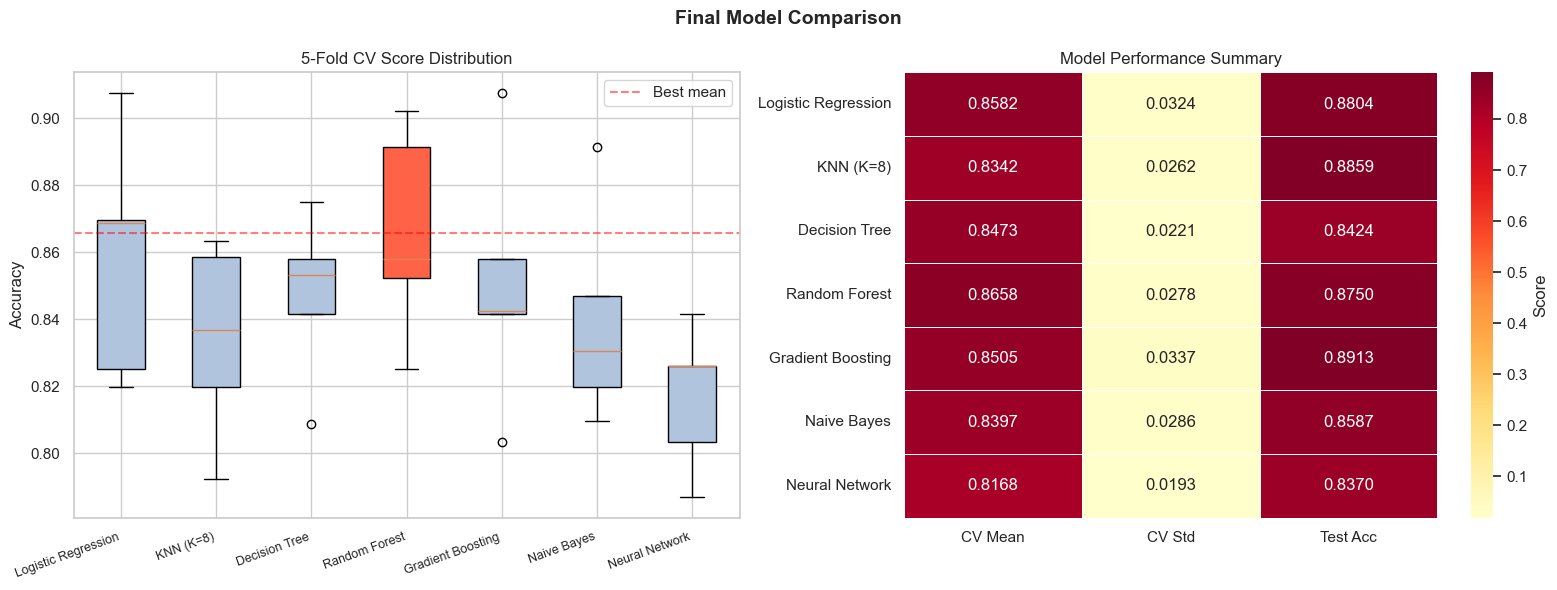


🏆 WINNER: Random Forest
   CV Mean Accuracy : 0.8658
   CV Std           : 0.0278
   Test Accuracy    : 0.8750
   Best params      : {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}

✅ Statistically superior to: KNN, Decision Tree, Neural Network
➖ Not significantly different from: Logistic Regression, Gradient Boosting, Naive Bayes


In [21]:
# ── SECTION 11: FINAL SUMMARY ────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: CV scores boxplot
cv_data = [cv_scores[m] for m in models]
bp = axes[0].boxplot(cv_data, patch_artist=True, notch=False)
colors_box = ['tomato' if m == 'Random Forest' else 'lightsteelblue' for m in models]
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
axes[0].set_xticklabels(models.keys(), rotation=20, ha='right', fontsize=9)
axes[0].set_ylabel('Accuracy')
axes[0].set_title('5-Fold CV Score Distribution')
axes[0].axhline(y=max([cv_scores[m].mean() for m in models]),
                color='red', linestyle='--', alpha=0.5, label='Best mean')
axes[0].legend()

# Right: summary table as heatmap
summary_data = pd.DataFrame({
    'CV Mean': [cv_scores[m].mean() for m in models],
    'CV Std':  [cv_scores[m].std()  for m in models],
    'Test Acc':[accuracy_score(y_test, p) for p in
                [y_pred_lr, y_pred_knn, y_pred_dt,
                 rf_best.predict(X_test), gb_best.predict(X_test),
                 y_pred_nb, y_pred_nn]]
}, index=models.keys()).round(4)

sns.heatmap(summary_data, annot=True, fmt='.4f', cmap='YlOrRd',
            ax=axes[1], linewidths=0.5, cbar_kws={'label': 'Score'})
axes[1].set_title('Model Performance Summary')
axes[1].tick_params(axis='y', rotation=0)

plt.suptitle('Final Model Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n🏆 WINNER: Random Forest")
print(f"   CV Mean Accuracy : {cv_scores['Random Forest'].mean():.4f}")
print(f"   CV Std           : {cv_scores['Random Forest'].std():.4f}")
print(f"   Test Accuracy    : {accuracy_score(y_test, rf_best.predict(X_test)):.4f}")
print(f"   Best params      : {rf_grid.best_params_}")
print("\n✅ Statistically superior to: KNN, Decision Tree, Neural Network")
print("➖ Not significantly different from: Logistic Regression, Gradient Boosting, Naive Bayes")